# Training Mask R-CNN

<!-- markdownlint-disable MD033-->
<div class="page-subtitle">
A practical, end-to-end workflow for training a Mask R-CNN model
</div>
<!-- markdownlint-enable MD033 -->

---

## 1. Motivation

On the previous page, `data` holds everything prepared for training: the images and labels directories, ready in the format `geoai` expects. This page uses that directly to train a Mask R-CNN model.

This is the page where the architecture from two pages ago and the data from the previous page become an actual trained model. As with the detection and segmentation training functions in earlier lessons, `geoai` hides most of the implementation behind a small set of parameters; understanding what each one controls is what lets you make good choices for your own project data later.

---

## 2. Core idea

`geoai.train_instance_segmentation_model()` runs the complete Mask R-CNN training pipeline: it builds the backbone, RPN, detection head, and mask head from the previous architecture page, and trains all of them together against a combined loss.

---

## 3. Workflow

Training an instance segmentation model requires configuring both structural parameters (which adapt the network architecture to your spatial data) and optimization hyperparameters (which control how the model learns). This section walks through setting up, executing, and evaluating a Mask R-CNN training pipeline on the prepared Luxembourg dataset.

---

### A. Dataset preparation

Before launching model training, we re-establish the dataset preparation pipeline to ensure all required directories and inputs are loaded:

In [ ]:
import os

# Apple Silicon (MPS) lacks some torchvision ops used by Mask R-CNN (e.g. nms);
# fall back to CPU for those. Must be set before torch is imported.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import geoai

geoai.download_ftw(countries=["luxembourg"], output_dir="ftw_data")
data = geoai.prepare_ftw("ftw_data", country="luxembourg")


---

### B. Core structural parameters

Three structural parameters adapt the Mask R-CNN model to the physical properties of our satellite imagery and labels:

```python
num_classes = 2
num_channels = 4
instance_labels = True

```

* **`num_classes=2` (Semantic Category Count):** Specifies background (`0`) and field (`1`). Although a single tile may contain dozens of individual field boundaries, all agricultural fields belong to the same semantic class. Object separation is handled by the mask head generating distinct masks per instance, not by assigning separate class indices to every field.
* **`num_channels=4` (Spectral Input Channels):** Matches the four Sentinel-2 bands in our prepared tiles: Red, Green, Blue, and Near-Infrared (NIR). As established in previous lessons, the NIR band provides essential spectral contrast for differentiating vegetation vigor and boundary edges that appear visually ambiguous in standard RGB imagery.
* **`instance_labels=True` (Preserving Object IDs):** Informs `geoai` that the label rasters already contain distinct integer values ($1, 2, 3 \dots$) representing unique field boundaries. The pipeline uses these values directly. Leave this parameter as `False` only when working with binary masks where individual instances must be derived automatically via connected-component labeling.

---

### C. The training pipeline

With the data prepared and parameters defined, we initialize and run the training function:

In [ ]:
# --- Estimated Execution Runtimes ---
# Apple Silicon (M3 Pro, 18 GB Unified Memory, PyTorch MPS): ~5.0 hours
# Google Colab  (NVIDIA T4 GPU, 16 GB VRAM, PyTorch CUDA):   ~1.5 hours

from pathlib import Path
import geoai

model_dir = Path("field_boundaries") / "models"

geoai.train_instance_segmentation_model(
    images_dir=data["images_dir"],
    labels_dir=data["labels_dir"],
    output_dir=str(model_dir),
    num_classes=2,
    num_channels=4,
    instance_labels=True,
    batch_size=4,
    num_epochs=20,
    learning_rate=0.005,
    val_split=0.2,
    visualize=True,
    verbose=True,
)


[W1104 14:06:18.264836000 MPSFallback.mm:34] Warning: The operator 'torchvision::nms' is not currently supported on the MPS backend and will fall back to run on the CPU. This may have performance implications. (function operator())


During training, model checkpoints and performance history logs are saved to `field_boundaries/models/`, with the highest-performing iteration stored as `best_model.pth`.

---

### D. Hyperparameters & GPU-memory

Hyperparameters control the optimization behavior during training:

* **`batch_size=4`:** Process four $256 \times 256$ tiles per step. Instance segmentation models consume significantly more GPU memory than standard classification or semantic segmentation networks because they extract, align, and process multiple candidate regions per image simultaneously.
* **`num_epochs=20`:** Sets twenty full passes through the training data, providing a balance between convergence and training speed for demonstration purposes. (Production workflows typically train for 50–100 epochs).
* **`learning_rate=0.005`:** Controls the step size of weight updates during gradient descent.
* **`val_split=0.2`:** Automatically reserves $20\%$ of the $724$-chip development pool as an internal validation split to monitor performance and detect overfitting during training.

```{admonition} Instance segmentation is GPU-memory hungry
:class: warning
If you encounter a CUDA Out-of-Memory (OOM) error, reduce `batch_size` from `4` to `2`. If memory pressure persists, adjust the tile size or choose a lighter backbone architecture (e.g., ResNet-34). Always scale batch size before altering network architecture.

```

```{tip} Run a "Smoke Test" First
Before committing to a multi-hour training run, run a 1-epoch "smoke test" with `num_epochs=1`. This quickly verifies that data loading pathways, CUDA device allocation, directory writes, and mask parsing function correctly without wasting GPU resources.

```

---

### E. Deconstructing the loss function

Unlike single-task models evaluated on a single loss value, Mask R-CNN optimizes a compound multi-task loss ($L_{\text{total}}$) representing five separate model operations:

$$L_{\text{total}} = L_{\text{rpn\_cls}} + L_{\text{rpn\_box}} + L_{\text{cls}} + L_{\text{box}} + L_{\text{mask}}$$

| Loss Component | Description | Diagnostic Meaning if High |
| --- | --- | --- |
| **$L_{\text{rpn\_cls}}$ (RPN Objectness)** | Evaluates whether the RPN correctly identifies regions containing objects. | Model struggles to find candidate features in the scene. |
| **$L_{\text{rpn\_box}}$ (RPN Box Proposal)** | Measures initial coarse anchor box alignment. | Candidate proposal boxes are poorly aligned with true features. |
| **$L_{\text{cls}}$ (Class Prediction)** | Evaluates classification of proposal regions (e.g., field vs. background). | Model misclassifies identified object proposals. |
| **$L_{\text{box}}$ (Box Refinement)** | Measures boundary accuracy of the refined detection bounding box. | Final bounding boxes are loose or misaligned. |
| **$L_{\text{mask}}$ (Mask Prediction)** | Evaluates binary pixel accuracy within each bounding box ($28 \times 28$ grid). | Predicted internal field shapes fail to match true geometric boundaries. |

Monitoring individual loss terms during training helps isolate specific model weaknesses—such as identifying whether poor final outputs stem from missed detections ($L_{\text{rpn\_cls}}$) or inaccurate edge boundaries ($L_{\text{mask}}$).

---

### F. Inspecting training history

After training completes, plot the metric history to evaluate convergence and generalization:

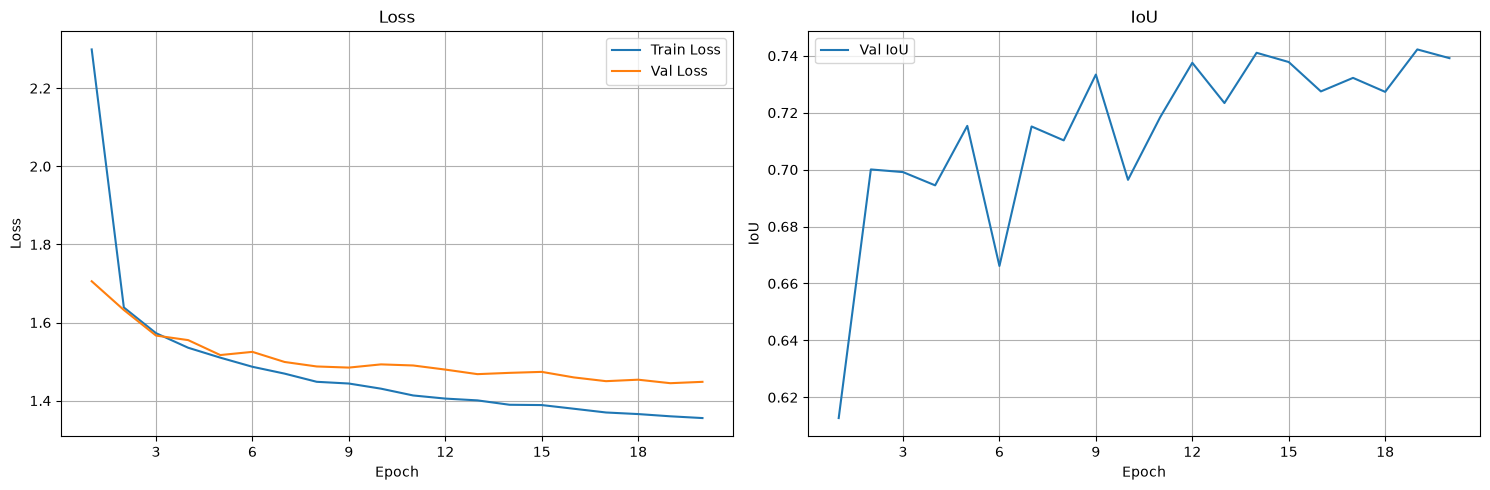

,epoch,train_loss,val_loss,val_iou
0,1,2.299260,1.705641,0.612708
1,2,1.638531,1.632130,0.700062
2,3,1.572768,1.566577,0.699132
3,4,1.535432,1.554964,0.694474
4,5,1.510025,1.516693,0.715369
5,6,1.486649,1.524852,0.666144
6,7,1.469141,1.498984,0.715160
7,8,1.448196,1.487469,0.710276
8,9,1.443779,1.484588,0.733401
9,10,1.430588,1.492794,0.696411


In [3]:
geoai.plot_performance_metrics(
    history_path=str(model_dir / "training_history.pth"),
    figsize=(15, 5),
    verbose=True,
)


When evaluating training curves, look for structural health indicators rather than focusing solely on final numeric values:

```text
Healthy Training                     Overfitting Warning
Loss                                 Loss
 │  ─── Training                      │  ─── Training
 │  --- Validation                    │  --- Validation
 │ \                                  │ \
 │  \__                               │  \__      /----------- (Val rises)
 │     \________                      │     \____/
 └───────────────── Epochs            └───────────────── Epochs

```

* **Healthy Convergence:** Both training and validation loss decrease steadily and level off together. Validation IoU improves in tandem with training metrics.
* **Overfitting:** Training loss continues to decrease while validation loss plateaus or increases. This indicates the model is memorizing training tile artifacts rather than learning generalizable boundary patterns.

```{important}
Training and validation curves reflect model optimization on development data. They are not a substitute for evaluating final inference performance on independent test datasets.

```

---

### G. Reproducibility

To maintain scientific reproducibility across model iterations, explicitly record model parameters, environment settings, and data lineage for every training run:

In [4]:
experiment_metadata = {
    "model_architecture": "mask_rcnn_resnet50_fpn",
    "dataset": "FTW_Luxembourg",
    "num_classes": 2,
    "num_channels": 4,
    "bands": ["Red", "Green", "Blue", "NIR"],
    "spatial_resolution": "10m",
    "batch_size": 4,
    "num_epochs": 20,
    "learning_rate": 0.005,
    "val_split": 0.2,
    "instance_labels": True,
}

experiment_metadata


{'model_architecture': 'mask_rcnn_resnet50_fpn',
 'dataset': 'FTW_Luxembourg',
 'num_classes': 2,
 'num_channels': 4,
 'bands': ['Red', 'Green', 'Blue', 'NIR'],
 'spatial_resolution': '10m',
 'batch_size': 4,
 'num_epochs': 20,
 'learning_rate': 0.005,
 'val_split': 0.2,
 'instance_labels': True}

Documenting dataset versions, spectral channel ordering, spatial resolution, and hyperparameter configurations ensures your geospatial deep learning workflows remain fully interpretable and reproducible.

---

## 4. Common pitfalls

* **Setting `batch_size` too high and hitting out-of-memory errors.** Reduce it before trying other fixes; this is the most common practical obstacle in this lesson.
* **Forgetting `instance_labels=True` with pre-labeled instance data.** Leaving it at the wrong setting means the model either ignores useful existing instance IDs or is fed IDs it was not expecting.
* **Assuming `num_classes=2` is an error because there are many fields.** It is correct: class count and instance count are independent, exactly the class-versus-instance distinction from two pages ago.
* **Reading only the total loss, not its components.** If training seems to stall, checking which specific loss component dominates can point you toward the actual problem faster than staring at one aggregate number.

---

## 5. Mini task

Training on your laptop's 8 GB GPU raises an out-of-memory error at `batch_size=8`. List two things you would try, in order, before concluding the task is infeasible on your hardware.

:::{dropdown} Sample solution
:class: note

First, reduce `batch_size` to something like 2 or 4, which directly reduces how many regions the model processes simultaneously and is the most common and effective fix for this specific error. If that alone does not resolve it, consider exporting smaller training tiles or choosing a lighter backbone encoder, both mentioned as further options for constrained GPU memory; only after trying these would concluding the task is infeasible on the available hardware be reasonable.
:::

---

## 6. Key takeaways

* `num_classes=2` (background and field) is correct even with many field instances, since instance separation comes from the mask head, not from class count.
* `instance_labels=True` tells `geoai` to use existing per-object instance IDs directly, matching how FTW masks are already structured.
* Instance segmentation training typically needs more GPU memory than semantic segmentation; reducing `batch_size` is the first fix for out-of-memory errors.
* The total training loss combines RPN, classification, box-regression, and mask losses; a dominant component can point to a specific problem.
* Watch the training-versus-validation loss gap for overfitting, the same check used throughout this course.

### Further reading

* OpenGeoAI, ["Train Instance Segmentation Model"](https://opengeoai.org/examples/train_instance_segmentation_model/) — the full, runnable notebook this workflow is based on.